In [26]:
import numpy as np
import matplotlib.pyplot as plt
import japanize_matplotlib

In [27]:
# 1. 著者が観測した電車間隔（秒）
observed_gap_times = np.array([
    428, 705, 407, 465, 433, 425, 204, 506, 143, 351,
    450, 598, 464, 749, 341, 586, 754, 256, 378, 435,
    176, 405, 360, 519, 648, 374, 483, 537, 578, 534,
    577, 619, 538, 331, 186, 629, 193, 360, 660, 484,
    512, 315, 457, 404, 740, 388, 357, 485, 567, 160,
    428, 387, 901, 187, 622, 616, 585, 474, 442, 499,
    437, 620, 351, 286, 373, 232, 393, 745, 636, 758
], dtype=float)

In [28]:
# 2.
zs = observed_gap_times / 60  # 秒を分に変換
qs = np.linspace(0,20,101) # 0分から20分までの等間隔の点を生成

# KDE
n = len(zs)
bandwidth = zs.std(ddof=1) * n **(-1/5)  # Silverman's rule of thumb
kde = np.zeros_like(qs)

z_scores = (qs[:,None] - zs[None,:]) / bandwidth

pmf_z = (
    np.exp(-0.5 * z_scores**2).mean(axis=1)
    / (bandwidth * np.sqrt(2 * np.pi))
)

データ件数: 70
平均電車間隔：7.77分
帯域幅：1.17分


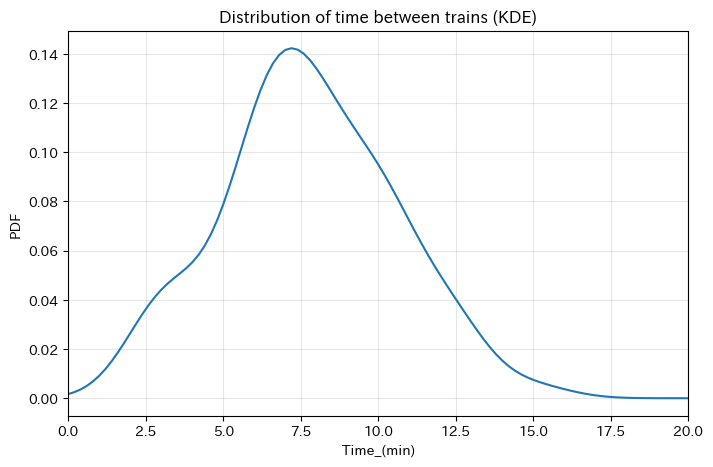

In [29]:
plt.figure(figsize=(8,5))
plt.plot(qs, pmf_z)
plt.xlabel("Time_(min)")
plt.ylabel("PDF")
plt.title("Distribution of time between trains (KDE)")
plt.xlim(0,20)
plt.grid(alpha=0.3)

print("データ件数:", n)
print(f"平均電車間隔：{zs.mean():.2f}分")
print(f"帯域幅：{bandwidth:.2f}分")

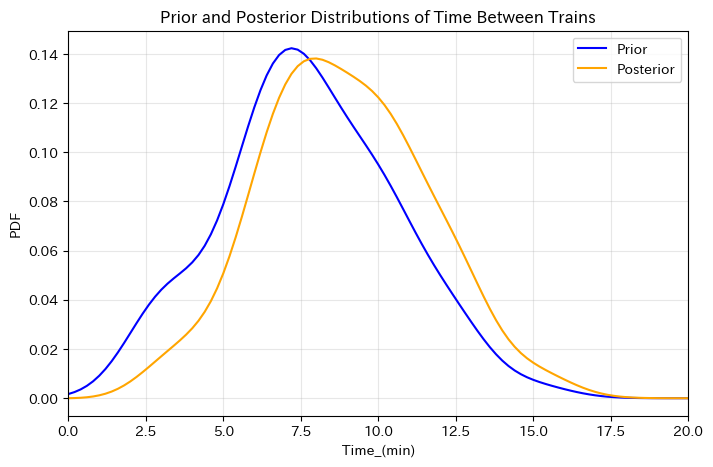

In [30]:
# 電車間隔の分布（事前分布）
prior_z = pmf_z.copy()

# 長い間隔ほど、ランダムな乗客が到着しやすい
posterior_z = pmf_z * qs

# 正規化
dx = qs[1] - qs[0]
posterior_z /= (posterior_z.sum() * dx)

plt.figure(figsize=(8,5))
plt.plot(qs, prior_z, label="Prior", color="blue")
plt.plot(qs, posterior_z, label="Posterior", color="orange")
plt.xlabel("Time_(min)")
plt.ylabel("PDF")
plt.title("Prior and Posterior Distributions of Time Between Trains")
plt.xlim(0,20)
plt.legend()
plt.grid(alpha=0.3)

In [31]:
prior_mean = (qs * prior_z).sum() * dx
print(f"事前分布の平均電車間隔：{prior_mean:.2f}分")

posterior_mean = (qs * posterior_z).sum() * dx
print(f"事後分布の平均電車間隔：{posterior_mean:.2f}分")

事前分布の平均電車間隔：7.77分
事後分布の平均電車間隔：8.90分


In [32]:
import thinkbayes

gap_times = observed_gap_times

xs = range(10, 1210,10)

pdf_z = thinkbayes.EstimatedPdf(gap_times)
pmf_z = pdf_z.MakePmf(xs)

def BiasPmf(pmf):
    new_pmf = pmf.Copy()
    for x, p in pmf.Items():
        new_pmf.Mult(x,x)
    new_pmf.Normalize()
    return new_pmf

pmf_zb = BiasPmf(pmf_z)

平均電車間隔（実際の分布）：7.78分
平均電車間隔（バイアス分布）：8.90分


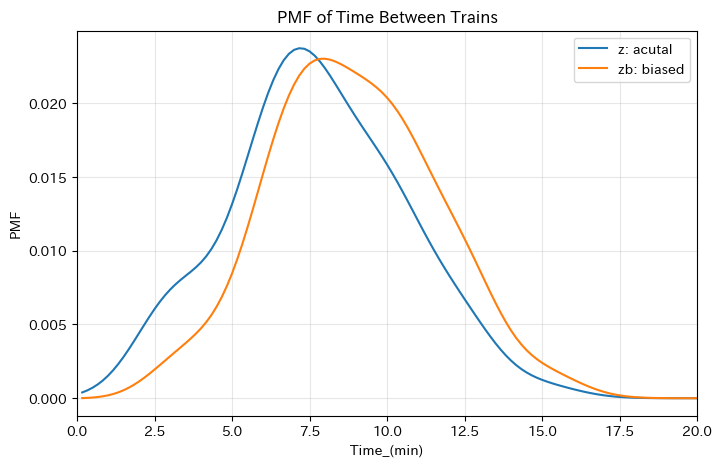

In [33]:
z_items = sorted(pmf_z.Items())
zb_items = sorted(pmf_zb.Items())

plt.figure(figsize=(8,5))
plt.plot(
    [x / 60 for x, p in z_items],
    [p for x, p in z_items],
    label="z: acutal"
)

plt.plot(
    [x / 60 for x, p in zb_items],
    [p for x, p in ab_items],
    label = "zb: biased"
)

plt.xlabel("Time_(min)")
plt.ylabel("PMF")
plt.title("PMF of Time Between Trains")
plt.xlim(0,20)
plt.legend()
plt.grid(alpha=0.3)

print(f"平均電車間隔（実際の分布）：{pmf_z.Mean()/60:.2f}分")
print(f"平均電車間隔（バイアス分布）：{pmf_zb.Mean()/60:.2f}分")

In [34]:
pmf = thinkbayes.Pmf()
pmf.Set(5, 0.5)
pmf.Set(10, 0.5)

pmf_biased = BiasPmf(pmf)

print("元のPMF:", list(pmf.Items()))
print("バイアス分布:", list(pmf_biased.Items()))

元のPMF: [(5, 0.5), (10, 0.5)]
バイアス分布: [(5, 0.3333333333333333), (10, 0.6666666666666666)]
